# Linear buckling analysis

Three linear buckling analyses of flat plates under a compression along
$x$:

1. a simply supported square isotropic plate, against the buckling
   coefficient $k_c = 4$ of the closed-form solution [1], with the
   geometric stiffness matrix of `update_KG` computed with a linear static
   solution, and the same eigenvalue problem solved with `structsolve.lb`;
2. the same plate with clamped loaded edges, against the exact buckling
   coefficient of Pflüger [2];
3. a laminated plate, with the geometric stiffness matrix of
   `update_KG_cte_N` for uniform membrane forces and with that of
   `update_KG` of a static solution, comparing the two sets of load
   multipliers.

The same models are checked in `tests/test_linear_buckling_iso_SSSS.py`,
`tests/test_linear_buckling_iso_CCSS.py`,
`tests/test_linear_buckling_cte_N.py` and `tests/test_linear_buckling.py`.

## Theory

Under the in-plane load $\lambda \boldsymbol{F}_{ext}$ a flat plate with
$\boldsymbol{B} = \boldsymbol{0}$ has the linear pre-buckling state
$\lambda \boldsymbol{u}_0$, $\boldsymbol{K}_{C0}\boldsymbol{u}_0 =
\boldsymbol{F}_{ext}$, without deflection. The tangent stiffness matrix
along this path is $\boldsymbol{K}_{C0} + \lambda
\boldsymbol{K}_G(\boldsymbol{u}_0)$, since $\boldsymbol{K}_G$ is linear in
the displacements, and a bifurcation occurs where it becomes singular:

$$
(\boldsymbol{K}_{C0} + \lambda \boldsymbol{K}_G) \boldsymbol{\phi} =
\boldsymbol{0}
$$

with the load multipliers $\lambda$ and the buckling modes
$\boldsymbol{\phi}$, restricted to the unconstrained degrees of freedom.
$\boldsymbol{K}_{C0}$ is positive definite and $\boldsymbol{K}_G$ symmetric
and indefinite. `eigsh` is called with `A = KG` and `M = KC0`, i.e. it
solves the equivalent problem $\boldsymbol{K}_G \boldsymbol{\phi} = \mu
\boldsymbol{K}_{C0} \boldsymbol{\phi}$ with $\mu = -1/\lambda$, in the
shift-invert mode `'cayley'`, and the load multipliers are recovered as
$\lambda = -1/\mu$. With a reference load of a unit compressive force per
unit length, the load multipliers are the critical forces per unit length.

The imports, and two helpers used in the three sections: `Mesh` builds the
nodes, the elements and $\boldsymbol{K}_{C0}$ of a rectangular plate of
$n_x$ by $n_y$ nodes, assembles $\boldsymbol{K}_G$ and gives the consistent
edge load; `w_field` interpolates $w$ inside the elements for the plots of
the buckling modes.

In [1]:
%matplotlib inline
import numpy as np
from numpy import isclose
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import eigsh, spsolve
from scipy.optimize import brentq
import matplotlib.pyplot as plt
from composites import isotropic_plate, laminated_plate
from structsolve import lb

from bfscplate2d import (BFSCPlate2D, update_KC0, update_KG, update_KG_cte_N,
        DOF, KC0_SPARSE_SIZE, KG_SPARSE_SIZE, DOUBLE, INT)
from bfscplate2d.quadrature import get_points_weights

In [2]:
class Mesh(object):
    """Rectangular plate of a by b on nx by ny nodes, with KC0 assembled.

    Node connectivity similar to Nastran's CQUAD4:

        4 ________ 3
         |       |
         |       |   --> x
         |_______|
        1         2
    """
    def __init__(self, a, b, nx, ny, ABD, nint=4):
        self.a, self.b, self.nx, self.ny, self.nint = a, b, nx, ny, nint
        self.points, self.weights = get_points_weights(nint=nint)
        xlin = np.linspace(0, a, nx)
        ylin = np.linspace(0, b, ny)
        self.xmesh, self.ymesh = np.meshgrid(xlin, ylin)
        ncoords = np.vstack((self.xmesh.T.flatten(), self.ymesh.T.flatten())).T
        self.x, self.y = ncoords[:, 0], ncoords[:, 1]
        nids = 1 + np.arange(ncoords.shape[0])
        self.nid_pos = nid_pos = dict(zip(nids, np.arange(len(nids))))
        nids_mesh = nids.reshape(nx, ny)
        n1s = nids_mesh[:-1, :-1].flatten()
        n2s = nids_mesh[1:, :-1].flatten()
        n3s = nids_mesh[1:, 1:].flatten()
        n4s = nids_mesh[:-1, 1:].flatten()
        num_elements = len(n1s)
        self.N = N = DOF*nx*ny
        Kr = np.zeros(KC0_SPARSE_SIZE*num_elements, dtype=INT)
        Kc = np.zeros(KC0_SPARSE_SIZE*num_elements, dtype=INT)
        Kv = np.zeros(KC0_SPARSE_SIZE*num_elements, dtype=DOUBLE)
        self.KGr = np.zeros(KG_SPARSE_SIZE*num_elements, dtype=INT)
        self.KGc = np.zeros(KG_SPARSE_SIZE*num_elements, dtype=INT)
        self.KGv = np.zeros(KG_SPARSE_SIZE*num_elements, dtype=DOUBLE)
        init_k_KC0 = 0
        init_k_KG = 0
        self.plates = []
        for n1, n2, n3, n4 in zip(n1s, n2s, n3s, n4s):
            plate = BFSCPlate2D()
            plate.n1, plate.n2, plate.n3, plate.n4 = n1, n2, n3, n4
            plate.c1 = DOF*nid_pos[n1]
            plate.c2 = DOF*nid_pos[n2]
            plate.c3 = DOF*nid_pos[n3]
            plate.c4 = DOF*nid_pos[n4]
            plate.ABD = ABD
            plate.lex = a/(nx - 1)
            plate.ley = b/(ny - 1)
            plate.init_k_KC0 = init_k_KC0
            plate.init_k_KG = init_k_KG
            update_KC0(plate, self.points, self.weights, Kr, Kc, Kv)
            init_k_KC0 += KC0_SPARSE_SIZE
            init_k_KG += KG_SPARSE_SIZE
            self.plates.append(plate)
        self.KC0 = coo_matrix((Kv, (Kr, Kc)), shape=(N, N)).tocsc()

    def KG(self, u):
        """K_G of update_KG with the displacements u."""
        self.KGv *= 0
        for plate in self.plates:
            update_KG(u, plate, self.points, self.weights,
                      self.KGr, self.KGc, self.KGv)
        return coo_matrix((self.KGv, (self.KGr, self.KGc)),
                          shape=(self.N, self.N)).tocsc()

    def KG_cte_N(self, Nxx, Nyy, Nxy):
        """K_G of update_KG_cte_N with the same membrane forces in every
        element."""
        self.KGv *= 0
        for plate in self.plates:
            update_KG_cte_N(Nxx, Nyy, Nxy, plate, self.points, self.weights,
                            self.KGr, self.KGc, self.KGv)
        return coo_matrix((self.KGv, (self.KGr, self.KGc)),
                          shape=(self.N, self.N)).tocsc()

    def edge_load_x(self, Nxx):
        """Consistent load of a compressive force per unit length -Nxx at
        x = 0 and x = a, integrated with the rows Su at xi = -1 and +1."""
        x = self.x
        fext = np.zeros(self.N)
        for plate in self.plates:
            pos1 = self.nid_pos[plate.n1]
            pos3 = self.nid_pos[plate.n3]
            if isclose(x[pos3], self.a):
                sign, xi = +1, +1
            elif isclose(x[pos1], 0):
                sign, xi = -1, -1
            else:
                continue
            indices = np.concatenate([np.arange(c, c + DOF) for c in
                                      (plate.c1, plate.c2, plate.c3, plate.c4)])
            fe = np.zeros(4*DOF)
            for j in range(self.nint):
                plate.update_Su(xi, self.points[j])
                fe += plate.ley/2*self.weights[j]*np.asarray(plate.Su)*sign*Nxx
            fext[indices] += fe
        return fext

In [3]:
def w_field(plates, u, nx, ny, n=9):
    """The deflection w interpolated with the rows Sw of each element on
    n by n points per element, for the contour plots."""
    lex, ley = plates[0].lex, plates[0].ley
    X = np.linspace(0, (nx - 1)*lex, (nx - 1)*(n - 1) + 1)
    Y = np.linspace(0, (ny - 1)*ley, (ny - 1)*(n - 1) + 1)
    W = np.zeros((Y.size, X.size))
    xis = np.linspace(-1, 1, n)
    for plate in plates:
        ue = np.concatenate([u[c:c + DOF] for c in
                             (plate.c1, plate.c2, plate.c3, plate.c4)])
        pos1 = plate.c1//DOF
        ix0, iy0 = pos1//ny, pos1 % ny
        for i, xi in enumerate(xis):
            for j, eta in enumerate(xis):
                plate.update_Sw(xi, eta)
                W[iy0*(n - 1) + j, ix0*(n - 1) + i] = np.asarray(plate.Sw) @ ue
    Xmesh, Ymesh = np.meshgrid(X, Y)
    return Xmesh, Ymesh, W

## 1. Simply supported square plate

The critical force per unit length of the simply supported plate of sides
$a$ and $b$ under a uniform compression $N_{xx}$ is [1]

$$
N_{xx,cr} = k_c \frac{\pi^2 D}{b^2}, \qquad
D = \frac{E h^3}{12 (1 - \nu^2)}, \qquad
k_c = \left( \frac{m b}{a} + \frac{a}{m b} \right)^2
$$

with $m$ the number of half-waves along $x$, minimum $k_c = 4$ for
$m = a/b = 1$. The plate has $a = b = 3$ m, $h = 1$ mm, $E = 200$ GPa and
$\nu = 0.3$, on a mesh of 5 by 5 nodes.

Along an edge $x$ = constant the interpolated $w$ depends only on $w$ and
$w_{,y}$ at the two nodes of the edge, so the simply supported edge
constrains both ($w$ and $w_{,x}$ on the edges $y$ = constant), while
$w_{,xy}$ stays free, also at the corners. The in-plane rigid-body motions
are removed by point supports, $u$ at the middle nodes of the edges $y = 0$
and $y = b$ and $v$ at the middle nodes of the edges $x = 0$ and $x = a$.
The unit compression is a consistent edge load, integrated with the rows
of `BFSCPlate2D.update_Su` at $\xi = \pm 1$, and $\boldsymbol{K}_G$ comes
from the linear static solution $\boldsymbol{u}_0$ of this load.

In [4]:
# geometry, material and mesh
a = 3.  # along x
b = 3.  # along y
E = 200e9
nu = 0.3
h = 0.001
nx, ny = 5, 5
lam = isotropic_plate(thickness=h, E=E, nu=nu)
mesh = Mesh(a, b, nx, ny, lam.ABD)
x, y = mesh.x, mesh.y
print('elements', len(mesh.plates), ', degrees of freedom', mesh.N)

# simply supported: w and its derivative along the edge
bk = np.zeros(mesh.N, dtype=bool)
edges_x = isclose(x, 0) | isclose(x, a)
edges_y = isclose(y, 0) | isclose(y, b)
bk[6::DOF] = edges_x | edges_y
bk[8::DOF] = edges_x
bk[7::DOF] = edges_y
# point supports
bk[0::DOF] = isclose(x, a/2) & edges_y
bk[3::DOF] = isclose(y, b/2) & edges_x
bu = ~bk

# unit compressive force per unit length and pre-buckling state
fext = mesh.edge_load_x(Nxx=-1.)
Kuu = mesh.KC0[bu, :][:, bu]
u0 = np.zeros(mesh.N)
u0[bu] = spsolve(Kuu, fext[bu])

# linear buckling
KGuu = mesh.KG(u0)[bu, :][:, bu]
num_eigenvalues = 5
eigvals, eigvecsu = eigsh(A=KGuu, k=num_eigenvalues, which='SM', M=Kuu,
                          tol=1e-6, sigma=1., mode='cayley')
eigvals = -1./eigvals
eigvecs = np.zeros((mesh.N, num_eigenvalues))
eigvecs[bu, :] = eigvecsu

D = E*h**3/(12*(1 - nu**2))
Nxxcr_ref = 4*np.pi**2*D/b**2
kc = eigvals[0]/(np.pi**2*D/b**2)
print()
print('%-22s %12s %12s %12s' % ('', 'computed', 'reference', 'rel. diff.'))
print('%-22s %12.4f %12.4f %+11.4f%%' % ('N_xx,cr (N/m)', eigvals[0],
      Nxxcr_ref, 100*(eigvals[0] - Nxxcr_ref)/Nxxcr_ref))
print('%-22s %12.5f %12.5f %+11.4f%%' % ('k_c', kc, 4., 100*(kc - 4)/4))

elements 16 , degrees of freedom 250

                           computed    reference   rel. diff.
N_xx,cr (N/m)               80.3595      80.3387     +0.0260%
k_c                         4.00104      4.00000     +0.0260%


The same eigenvalue problem solved with the linear buckling solver of
structsolve, `structsolve.lb(Kuu, KGuu)`, which returns the load multipliers
$\lambda$ directly:

In [5]:
eigvals_lb, _ = lb(Kuu, KGuu, num_eigvalues=num_eigenvalues,
                   symmetric=True, silent=True)
print('%-6s %16s %16s %12s' % ('mode', 'eigsh', 'structsolve.lb',
                               'rel. diff.'))
for i in range(num_eigenvalues):
    print('%-6d %16.8f %16.8f %12.2e' % (i + 1, eigvals[i], eigvals_lb[i],
          (eigvals_lb[i] - eigvals[i])/eigvals[i]))

mode              eigsh   structsolve.lb   rel. diff.
1           80.35952190      80.35952190     2.09e-14
2          126.13440693     126.13440693     4.36e-14
3          229.17568919     229.17568919     2.90e-14
4          322.61978249     322.61978249     1.52e-13
5          383.35979689     383.35979684    -1.29e-10


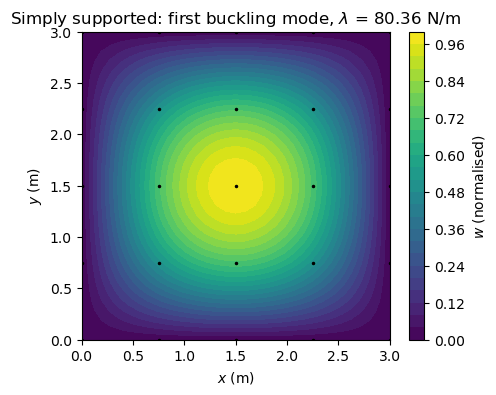

In [6]:
Xf, Yf, Wf = w_field(mesh.plates, eigvecs[:, 0], nx, ny)
Wf /= Wf[np.unravel_index(np.abs(Wf).argmax(), Wf.shape)]
plt.figure(figsize=(5, 4))
plt.gca().set_aspect('equal')
plt.contourf(Xf, Yf, Wf, levels=30, cmap='viridis')
plt.colorbar(label='$w$ (normalised)')
plt.plot(x, y, 'k.', ms=3)
plt.xlabel('$x$ (m)')
plt.ylabel('$y$ (m)')
plt.title('Simply supported: first buckling mode, $\\lambda$ = %.2f N/m'
          % eigvals[0])
plt.show()

The computed critical force per unit length, 80.36 N/m, gives
$k_c = 4.0010$, 0.026 % above the closed-form value; with 9 by 9 nodes the
difference drops to 0.0016 %. The first mode has one half-wave in each
direction, $m = 1$. The five load multipliers of `eigsh` and of
`structsolve.lb` agree within a relative difference of $1.3 \times
10^{-10}$.

## 2. Square plate with clamped loaded edges

The same plate, with the loaded edges $x = 0$ and $x = a$ clamped and the
edges $y = 0$ and $y = b$ simply supported. The interpolated $w_{,x}$ along
an edge $x$ = constant depends only on $w_{,x}$ and $w_{,xy}$ at the two
nodes of the edge, so the clamped edge adds both to the constraints of the
simply supported one. The buckling coefficient

$$
k_c = \frac{N_{xx,cr} \, b^2}{\pi^2 D}
$$

is compared with the exact solution of this plate under a uniform
compression [2]. With $w = \sin(\pi y/b) f(x)$ the buckling mode is
symmetric or antisymmetric about $x = a/2$, and $f = 0$, $f_{,x} = 0$ on
the loaded edges give the characteristic equations

$$
\lambda_1 \tan \frac{\lambda_1 \alpha}{2}
- \lambda_2 \tan \frac{\lambda_2 \alpha}{2} = 0, \qquad
\lambda_2 \tan \frac{\lambda_1 \alpha}{2}
- \lambda_1 \tan \frac{\lambda_2 \alpha}{2} = 0, \qquad
\lambda_{1,2} = \frac{\pi}{2} \left( \sqrt{k_c} \pm
\sqrt{k_c - 4} \right)
$$

of the symmetric and of the antisymmetric modes, with $\alpha = a/b$; the
smallest root $k_c$ of the two is the reference. The roots are bracketed on
a grid of $k_c > 4$ and refined with `brentq`, discarding the sign changes
at the poles of the tangent. Bruhn [3], Fig. C5.2, case C, gives the same
case as a curve, from which $k_c \approx 6.6$ is read for the square
plate.

In [7]:
# simply supported edges, as in section 1
bk = np.zeros(mesh.N, dtype=bool)
bk[6::DOF] = edges_x | edges_y
bk[8::DOF] = edges_x
bk[7::DOF] = edges_y
# clamped loaded edges: the normal slope and its derivative along the edge
bk[7::DOF] |= edges_x
bk[9::DOF] |= edges_x
# point supports
bk[0::DOF] = isclose(x, a/2) & edges_y
bk[3::DOF] = isclose(y, b/2) & edges_x
bu = ~bk

Kuu = mesh.KC0[bu, :][:, bu]
u0 = np.zeros(mesh.N)
u0[bu] = spsolve(Kuu, fext[bu])
KGuu = mesh.KG(u0)[bu, :][:, bu]
eigvals, eigvecsu = eigsh(A=KGuu, k=num_eigenvalues, which='SM', M=Kuu,
                          tol=1e-6, sigma=1., mode='cayley')
eigvals = -1./eigvals
eigvecs = np.zeros((mesh.N, num_eigenvalues))
eigvecs[bu, :] = eigvecsu

# exact buckling coefficient, smallest root of the characteristic equations
def lambdas(k):
    return (np.pi/2*(np.sqrt(k) + np.sqrt(k - 4)),
            np.pi/2*(np.sqrt(k) - np.sqrt(k - 4)))

def symmetric(k, alpha):
    l1, l2 = lambdas(k)
    return l1*np.tan(l1*alpha/2) - l2*np.tan(l2*alpha/2)

def antisymmetric(k, alpha):
    l1, l2 = lambdas(k)
    return l2*np.tan(l1*alpha/2) - l1*np.tan(l2*alpha/2)

alpha = a/b
ks = np.linspace(4. + 1e-9, 40., 100001)
roots = []
for func in (symmetric, antisymmetric):
    values = func(ks, alpha)
    for i in np.nonzero(np.sign(values[:-1]) != np.sign(values[1:]))[0]:
        k = brentq(func, ks[i], ks[i+1], args=(alpha,), xtol=1e-14)
        if abs(func(k, alpha)) < 1e-8:
            roots.append(k)
kc_exact = min(roots)

kc = eigvals[0]/(np.pi**2*D/b**2)
print('N_xx,cr = %.4f N/m' % eigvals[0])
print()
print('%-22s %12s %12s %12s' % ('', 'computed', 'reference', 'rel. diff.'))
print('%-22s %12.4f %12.4f %+11.3f%%' % ('k_c, exact [2]', kc, kc_exact,
      100*(kc - kc_exact)/kc_exact))
print('%-22s %12.4f %12.4f %+11.3f%%' % ('k_c, Bruhn [3]', kc, 6.6,
      100*(kc - 6.6)/6.6))

N_xx,cr = 136.2225 N/m

                           computed    reference   rel. diff.
k_c, exact [2]               6.7824       6.7432      +0.582%
k_c, Bruhn [3]               6.7824       6.6000      +2.764%


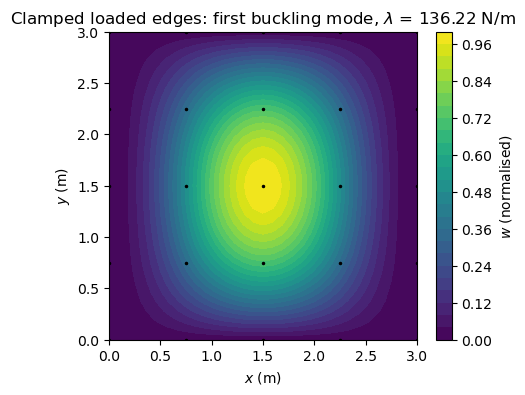

In [8]:
Xf, Yf, Wf = w_field(mesh.plates, eigvecs[:, 0], nx, ny)
Wf /= Wf[np.unravel_index(np.abs(Wf).argmax(), Wf.shape)]
plt.figure(figsize=(5, 4))
plt.gca().set_aspect('equal')
plt.contourf(Xf, Yf, Wf, levels=30, cmap='viridis')
plt.colorbar(label='$w$ (normalised)')
plt.plot(x, y, 'k.', ms=3)
plt.xlabel('$x$ (m)')
plt.ylabel('$y$ (m)')
plt.title('Clamped loaded edges: first buckling mode, $\\lambda$ = %.2f N/m'
          % eigvals[0])
plt.show()

The computed critical force per unit length, 136.22 N/m, gives
$k_c = 6.782$, 0.58 % above the exact value 6.7432. Refining the mesh,
$k_c$ converges to the exact value from above (6.746 with 9 by 9 nodes,
6.743 with 17 by 17 nodes). The value read from the figure of Bruhn is
2.1 % below the exact one, the precision of the reading. The clamped
loaded edges raise $k_c$ from 4.00 to 6.78, with the mode still of one
half-wave along $x$.

## 3. Laminated plate: uniform and computed membrane forces

A laminate $[0, 45, -45, 90, 90, -45, 45, 0]$ of plies of 1 mm with
$E_{11} = 142.5$ GPa, $E_{22} = 8.7$ GPa, $\nu_{12} = 0.28$ and
$G_{12} = G_{13} = G_{23} = 5.1$ GPa, symmetric, $\boldsymbol{B} =
\boldsymbol{0}$, on a plate of $a = 7$ m by $b = 3$ m with a mesh of 7 by 5
nodes. The four edges are simply supported, $u$ is constrained at $x = 0$
and $v$ at $y = 0$. $\boldsymbol{K}_G$ is computed in the two ways of
`bfscplate2d`:

- `update_KG_cte_N` with the membrane forces given for each element,
  positive in tension, without a static analysis: $\lambda$ multiplies these
  forces, and `Nxx = -1`, `Nyy = Nxy = 0` in every element give $\lambda$
  equal to the critical compressive force per unit length. This is exact
  for a pre-buckling state of uniform membrane forces;
- `update_KG` with the linear static solution of a compressive force per
  unit length of 1 N/m applied as nodal forces along $u$ on the edge
  $x = a$, half the force at the two corner nodes: the membrane forces are
  those of the plate with its boundary conditions and the actual
  distribution of the load.

There is no literature value for this plate; the two sets of load
multipliers are compared with each other. The edges are supported along
their whole length, with $w_{,y}$ constrained on the edges $x$ = constant
and $w_{,x}$ on the edges $y$ = constant. The tests
`tests/test_linear_buckling_cte_N.py` and `tests/test_linear_buckling.py`
use the same model and store these load multipliers.

In [9]:
# laminate, geometry and mesh
E11 = 142.5e9
E22 = 8.7e9
nu12 = 0.28
G12 = G13 = G23 = 5.1e9
laminaprop = (E11, E22, nu12, G12, G13, G23)
stack = [0, 45, -45, 90, 90, -45, 45, 0]
ply_thickness = 0.001
lam = laminated_plate(stack=stack, plyt=ply_thickness, laminaprop=laminaprop)
a = 7.  # along x
b = 3.  # along y
nx, ny = 7, 5
mesh3 = Mesh(a, b, nx, ny, lam.ABD)
x, y = mesh3.x, mesh3.y
print('elements', len(mesh3.plates), ', degrees of freedom', mesh3.N)

# simply supported edges, u at x = 0, v at y = 0
bk = np.zeros(mesh3.N, dtype=bool)
edges_x = isclose(x, 0) | isclose(x, a)
edges_y = isclose(y, 0) | isclose(y, b)
bk[6::DOF] = edges_x | edges_y
bk[8::DOF] = edges_x
bk[7::DOF] = edges_y
bk[0::DOF] = isclose(x, 0)
bk[3::DOF] = isclose(y, 0)
bu = ~bk
Kuu = mesh3.KC0[bu, :][:, bu]

elements 24 , degrees of freedom 350


### Uniform membrane forces, `update_KG_cte_N`

In [10]:
KGuu = mesh3.KG_cte_N(Nxx=-1., Nyy=0., Nxy=0.)[bu, :][:, bu]
eigvals_cte, eigvecsu = eigsh(A=KGuu, k=num_eigenvalues, which='SM', M=Kuu,
                              tol=1e-6, sigma=1., mode='cayley')
eigvals_cte = -1./eigvals_cte
eigvecs_cte = np.zeros((mesh3.N, num_eigenvalues))
eigvecs_cte[bu, :] = eigvecsu
print('load multipliers (N/m)', np.round(eigvals_cte, 2))

load multipliers (N/m) [ 9526.48 11741.15 12981.11 18881.34 27096.54]


### Membrane forces of a static solution, `update_KG`

The static solution under the nodal forces, and the membrane forces
$\{N_{xx}, N_{yy}, N_{xy}\}^T = \boldsymbol{A} \{u_{,x}, v_{,y}, u_{,y} +
v_{,x}\}^T$ at the nodes, from the nodal values of the derivatives, to see
how far the pre-buckling state is from the uniform one:

In [11]:
fext = np.zeros(mesh3.N)
Nxx = -1.
ftotal = Nxx*b
check = isclose(x, a) & ~isclose(y, 0) & ~isclose(y, b)
fext[0::DOF][check] = ftotal/(ny - 1)
check = isclose(x, a) & (isclose(y, 0) | isclose(y, b))
fext[0::DOF][check] = ftotal/(ny - 1)/2

u0 = np.zeros(mesh3.N)
u0[bu] = spsolve(Kuu, fext[bu])

A = np.asarray(lam.ABD)[:3, :3]
eps = np.vstack((u0[1::DOF], u0[5::DOF], u0[2::DOF] + u0[4::DOF]))
Nnodes = A @ eps
for name, Ni in zip(('N_xx', 'N_yy', 'N_xy'), Nnodes):
    print('%s at the nodes: min %+.4f, max %+.4f N/m' % (name, Ni.min(),
                                                         Ni.max()))

KGuu = mesh3.KG(u0)[bu, :][:, bu]
eigvals_st, eigvecsu = eigsh(A=KGuu, k=num_eigenvalues, which='SM', M=Kuu,
                             tol=1e-6, sigma=1., mode='cayley')
eigvals_st = -1./eigvals_st
eigvecs_st = np.zeros((mesh3.N, num_eigenvalues))
eigvecs_st[bu, :] = eigvecsu

print()
print('%-6s %16s %16s %12s' % ('mode', 'update_KG_cte_N', 'update_KG',
                               'rel. diff.'))
for i in range(num_eigenvalues):
    print('%-6d %16.4f %16.4f %+11.3f%%' % (i + 1, eigvals_cte[i],
          eigvals_st[i], 100*(eigvals_st[i] - eigvals_cte[i])/eigvals_cte[i]))

N_xx at the nodes: min -1.2039, max -0.6606 N/m
N_yy at the nodes: min -0.0892, max +0.1791 N/m
N_xy at the nodes: min -1.0013, max +1.0490 N/m

mode    update_KG_cte_N        update_KG   rel. diff.
1             9526.4814        9506.5712      -0.209%
2            11741.1538       11774.6494      +0.285%
3            12981.1097       12876.2631      -0.808%
4            18881.3390       18743.2043      -0.732%
5            27096.5363       26948.0053      -0.548%


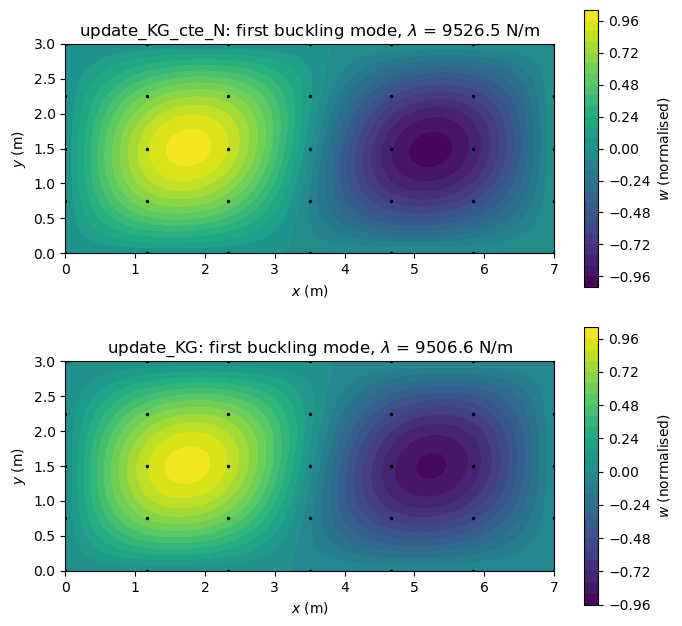

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(7, 6.5))
for ax, vecs, vals, name in zip(axes, (eigvecs_cte, eigvecs_st),
                                (eigvals_cte, eigvals_st),
                                ('update_KG_cte_N', 'update_KG')):
    Xf, Yf, Wf = w_field(mesh3.plates, vecs[:, 0], nx, ny)
    Wf /= Wf[np.unravel_index(np.abs(Wf).argmax(), Wf.shape)]
    ax.set_aspect('equal')
    cs = ax.contourf(Xf, Yf, Wf, levels=30, cmap='viridis')
    fig.colorbar(cs, ax=ax, label='$w$ (normalised)')
    ax.plot(x, y, 'k.', ms=3)
    ax.set_xlabel('$x$ (m)')
    ax.set_ylabel('$y$ (m)')
    ax.set_title('%s: first buckling mode, $\\lambda$ = %.1f N/m'
                 % (name, vals[0]))
fig.tight_layout()
plt.show()

The first mode has two half-waves along $x$ in both analyses. The load
multipliers of the static solution differ from those of the uniform
membrane forces by -0.21 % and +0.29 % for the first two modes, and by up
to -0.81 % for the next three. The pre-buckling state of the static
solution is not uniform: at the nodes $N_{xx}$ ranges from -1.20 to
-0.66 N/m instead of -1, with $N_{yy}$ from -0.09 to +0.18 N/m and
$N_{xy}$ from -1.00 to +1.05 N/m instead of zero, because the load is
applied as nodal forces on the $u$ degrees of freedom of the edge $x = a$,
and the constraints of $u$ at $x = 0$ and of $v$ at $y = 0$ restrain the
plate. `update_KG_cte_N` is exact for the uniform state, `update_KG`
represents the state that the actual load and supports produce; the two
coincide for a uniform pre-buckling state.

## References

1. Timoshenko, S. P., and Gere, J. M., *Theory of Elastic Stability*, 2nd ed., McGraw-Hill, New York, 1961.
2. Pflüger, A., *Stabilitätsprobleme der Elastostatik*, 3rd ed., Springer, Berlin, 1975, p. 410, table II, A, a, case 3, [doi:10.1007/978-3-662-09994-0](https://doi.org/10.1007/978-3-662-09994-0).
3. Bruhn, E. F., *Analysis and Design of Flight Vehicle Structures*, Jacobs Publishing, Indianapolis, 1973.